# 03 · Threshold sensitivity and statistical comparisons

The proxy label `High_Admission_Chance` depends on where the dataset's estimated Chance of Admit is
cut. This notebook repeats the evaluation at target thresholds 0.70, 0.75 and 0.80 and tests whether
the selected model improves on each baseline.

**Paired method.** For every record, out-of-fold probabilities are averaged over the ten repeats,
giving one cross-fitted prediction per record and model. The difference in balanced accuracy is then
assessed with a paired row-level bootstrap (95% CI) and a paired permutation test (two-sided p-value),
with Holm correction across the two baseline comparisons at each threshold.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "gradmit").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
TEAL, OCHRE, SLATE, BRICK = "#0B6E69", "#B7791F", "#6B7C80", "#B4452F"

from gradmit.baselines import CGPA_CUTOFF, MAJORITY
from gradmit.data import TARGET_THRESHOLDS, class_balance, load_data
from gradmit.modelling import MODEL_NAMES
from gradmit.reporting import build_paired_tests, build_threshold_sensitivity, load_outputs, oof_for
from gradmit.statistics import holm_correction, paired_comparison

df = load_data()
outputs = load_outputs()
selected = outputs["evaluation"]["selected_model"]
comparison, oof = outputs["comparison"], outputs["oof"]
print("selected model:", selected)

selected model: Logistic Regression


## Class distribution at each target threshold

In [2]:
balance = pd.DataFrame([class_balance(df, t) for t in TARGET_THRESHOLDS])
assert balance["n_positive"].tolist() == [300, 218, 155]
balance.assign(positive_share=lambda d: (d.positive_share * 100).round(1),
               majority_accuracy=lambda d: (d.majority_accuracy * 100).round(1))

,target_threshold,n,n_positive,n_negative,positive_share,majority_accuracy
0,0.70,500,300,200,60.0,60.0
1,0.75,500,218,282,43.6,56.4
2,0.80,500,155,345,31.0,69.0


## Paired tests, recomputed live

`build_paired_tests` is re-run on the committed cross-fitted predictions and compared with
`outputs/paired_tests.csv`.

In [3]:
n_resamples = int(outputs["paired"]["n_resamples"].iloc[0])
paired = build_paired_tests(oof, selected, n_resamples=n_resamples)
for col in ["difference", "ci_low", "ci_high", "p_value", "p_value_holm"]:
    assert np.allclose(paired[col], outputs["paired"][col], atol=2e-6), col
print(f"{n_resamples:,} bootstrap resamples and {n_resamples:,} permutations per comparison; matches the committed file")
paired.style.format({c: "{:+.4f}" for c in ["difference", "ci_low", "ci_high"]} | {"p_value": "{:.4f}", "p_value_holm": "{:.4f}"}).hide(axis="index")

10,000 bootstrap resamples and 10,000 permutations per comparison; matches the committed file


target_threshold,model,baseline,metric,difference,ci_low,ci_high,p_value,p_value_holm,significant,n_resamples
0.700000,Logistic Regression,Majority baseline,balanced_accuracy,+0.3608,+0.3281,+0.3915,0.0001,0.0002,True,10000
0.700000,Logistic Regression,CGPA cutoff baseline,balanced_accuracy,+0.0275,+0.0011,+0.0528,0.0380,0.0380,True,10000
0.750000,Logistic Regression,Majority baseline,balanced_accuracy,+0.3828,+0.3535,+0.4107,0.0001,0.0002,True,10000
0.750000,Logistic Regression,CGPA cutoff baseline,balanced_accuracy,+0.0027,-0.0197,+0.0248,0.7993,0.7993,False,10000
0.800000,Logistic Regression,Majority baseline,balanced_accuracy,+0.4108,+0.3819,+0.4383,0.0001,0.0002,True,10000
0.800000,Logistic Regression,CGPA cutoff baseline,balanced_accuracy,-0.0095,-0.0332,+0.0130,0.4214,0.4214,False,10000


raw p-values: [0.0001, 0.7993] -> Holm-adjusted: [0.0002, 0.7993]


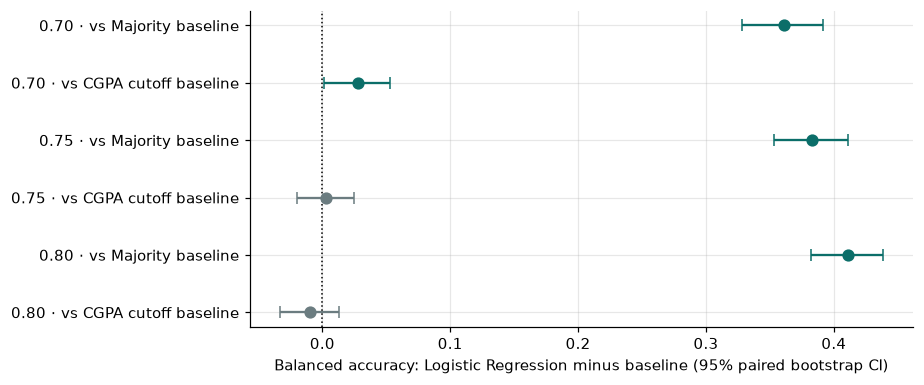

In [4]:
# Holm correction, spelled out for the default threshold.
block = paired[paired.target_threshold == 0.75]
raw = block["p_value"].tolist()
print("raw p-values:", [round(p, 4) for p in raw], "-> Holm-adjusted:", [round(p, 4) for p in holm_correction(raw)])

fig, ax = plt.subplots(figsize=(8.5, 3.6))
labels, ypos = [], []
for i, r in enumerate(paired.itertuples()):
    colour = TEAL if r.significant else SLATE
    ax.errorbar(r.difference, i, xerr=[[r.difference - r.ci_low], [r.ci_high - r.difference]],
                fmt="o", color=colour, capsize=4, ms=7)
    labels.append(f"{r.target_threshold:.2f} · vs {r.baseline}")
ax.axvline(0, color="black", lw=1, ls=":")
ax.set_yticks(range(len(labels)), labels); ax.invert_yaxis()
ax.set_xlabel(f"Balanced accuracy: {selected} minus baseline (95% paired bootstrap CI)")
plt.tight_layout(); plt.show()

In [5]:
lines = []
for r in paired.itertuples():
    claim = ("supported: the interval excludes zero and the Holm-corrected p-value is below 0.05" if r.significant
             else "not supported: the interval includes zero or the corrected p-value is not below 0.05")
    lines.append(f"- **{r.target_threshold:.2f}, vs {r.baseline}:** {r.difference:+.3f} "
                 f"(95% CI {r.ci_low:+.3f} to {r.ci_high:+.3f}, Holm p = {r.p_value_holm:.4f}). Improvement {claim}.")
display(Markdown("**Reading the tests.**\n" + "\n".join(lines)))

**Reading the tests.**
- **0.70, vs Majority baseline:** +0.361 (95% CI +0.328 to +0.392, Holm p = 0.0002). Improvement supported: the interval excludes zero and the Holm-corrected p-value is below 0.05.
- **0.70, vs CGPA cutoff baseline:** +0.028 (95% CI +0.001 to +0.053, Holm p = 0.0380). Improvement supported: the interval excludes zero and the Holm-corrected p-value is below 0.05.
- **0.75, vs Majority baseline:** +0.383 (95% CI +0.353 to +0.411, Holm p = 0.0002). Improvement supported: the interval excludes zero and the Holm-corrected p-value is below 0.05.
- **0.75, vs CGPA cutoff baseline:** +0.003 (95% CI -0.020 to +0.025, Holm p = 0.7993). Improvement not supported: the interval includes zero or the corrected p-value is not below 0.05.
- **0.80, vs Majority baseline:** +0.411 (95% CI +0.382 to +0.438, Holm p = 0.0002). Improvement supported: the interval excludes zero and the Holm-corrected p-value is below 0.05.
- **0.80, vs CGPA cutoff baseline:** -0.010 (95% CI -0.033 to +0.013, Holm p = 0.4214). Improvement not supported: the interval includes zero or the corrected p-value is not below 0.05.

## Threshold sensitivity table

In [6]:
sensitivity = build_threshold_sensitivity(df, comparison, paired, selected)
num = sensitivity.select_dtypes("number").columns
assert np.allclose(sensitivity[num], outputs["sensitivity"][num], atol=2e-6)
view = sensitivity[["target_threshold", "n_positive", "positive_share", "majority_accuracy",
                    "majority_balanced_accuracy", "cgpa_balanced_accuracy", "model_balanced_accuracy",
                    "model_balanced_accuracy_ci_low", "model_balanced_accuracy_ci_high", "cgpa_f1", "model_f1",
                    "cgpa_roc_auc", "model_roc_auc", "improvement_over_cgpa", "improvement_over_cgpa_ci_low",
                    "improvement_over_cgpa_ci_high", "improvement_over_cgpa_p_holm"]]
view.T.rename(columns=lambda i: f"threshold {sensitivity.target_threshold[i]:.2f}").style.format(precision=3)

,threshold 0.70,threshold 0.75,threshold 0.80
target_threshold,0.700,0.750,0.800
n_positive,300.000,218.000,155.000
positive_share,0.600,0.436,0.310
majority_accuracy,0.600,0.564,0.690
majority_balanced_accuracy,0.500,0.500,0.500
cgpa_balanced_accuracy,0.820,0.875,0.918
model_balanced_accuracy,0.862,0.881,0.910
model_balanced_accuracy_ci_low,0.832,0.847,0.877
model_balanced_accuracy_ci_high,0.892,0.915,0.943
cgpa_f1,0.837,0.859,0.877


## Stability of the model ranking

target_threshold,BA at 0.7,BA at 0.75,BA at 0.8,rank at 0.7,rank at 0.75,rank at 0.8
model,,,,,,
Logistic Regression,0.862,0.881,0.910,1,1,2
Random Forest,0.849,0.879,0.893,3,2,5
Hist Gradient Boosting,0.844,0.875,0.899,4,3,3
CGPA cutoff baseline,0.820,0.875,0.918,6,4,1
SVM (RBF),0.850,0.868,0.893,2,5,4
K-Nearest Neighbours,0.840,0.866,0.890,5,6,6


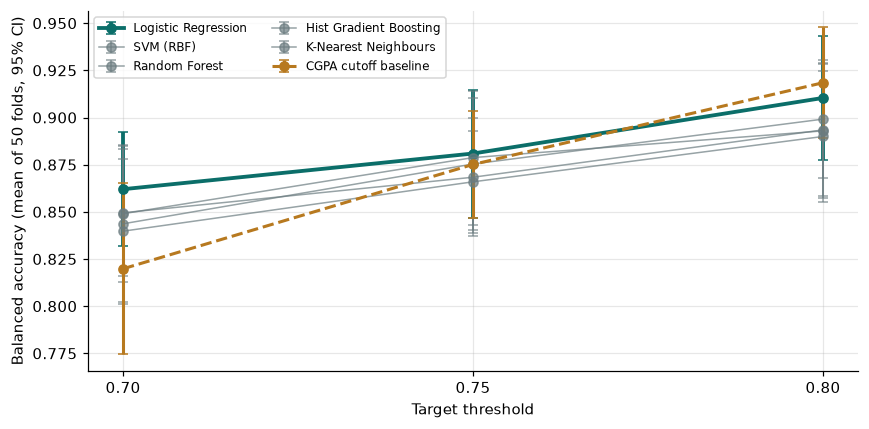

**Ranking stability.** Best model family by mean balanced accuracy: Logistic Regression at 0.70, Logistic Regression at 0.75, Logistic Regression at 0.80. The spread between the best and worst model family is 0.022 at 0.70, 0.015 at 0.75, 0.020 at 0.80, smaller than the width of any single model's confidence interval, so the order among model families is not stable evidence of anything. The CGPA cutoff baseline has a higher mean balanced accuracy than Logistic Regression at 1 of the 3 thresholds. The comparison that matters is the paired test against that baseline, above.

In [7]:
ml = comparison[comparison.model.isin(MODEL_NAMES) | (comparison.model == CGPA_CUTOFF)]
pivot = ml.pivot(index="model", columns="target_threshold", values="balanced_accuracy_mean")
ranks = pivot.rank(ascending=False).astype(int).add_prefix("rank at ")
display(pd.concat([pivot.add_prefix("BA at "), ranks], axis=1).sort_values("BA at 0.75", ascending=False).style.format(precision=3))

fig, ax = plt.subplots(figsize=(8, 4))
for model, grp in ml.groupby("model", sort=False):
    grp = grp.sort_values("target_threshold")
    style = dict(color=TEAL, lw=2.5) if model == selected else dict(color=OCHRE, lw=2, ls="--") if model == CGPA_CUTOFF else dict(color=SLATE, lw=1, alpha=0.7)
    ax.errorbar(grp.target_threshold, grp.balanced_accuracy_mean,
                yerr=[grp.balanced_accuracy_mean - grp.balanced_accuracy_ci_low, grp.balanced_accuracy_ci_high - grp.balanced_accuracy_mean],
                marker="o", capsize=3, label=model, **style)
ax.set(xticks=list(TARGET_THRESHOLDS), xlabel="Target threshold", ylabel="Balanced accuracy (mean of 50 folds, 95% CI)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

best = {f"{t:.2f}": b for t, b in zip(sensitivity.target_threshold, sensitivity.best_model_at_threshold)}
spread = (pivot.loc[list(MODEL_NAMES)].max() - pivot.loc[list(MODEL_NAMES)].min()).round(3).to_dict()
display(Markdown(
    "**Ranking stability.** Best model family by mean balanced accuracy: "
    + ", ".join(f"{b} at {t}" for t, b in best.items())
    + ". The spread between the best and worst model family is "
    + ", ".join(f"{v:.3f} at {t:.2f}" for t, v in spread.items())
    + ", smaller than the width of any single model's confidence interval, so the order among model families "
      "is not stable evidence of anything. The CGPA cutoff baseline has a higher mean balanced accuracy than "
    + f"{selected} at {int((pivot.loc[CGPA_CUTOFF] > pivot.loc[selected]).sum())} of the {len(TARGET_THRESHOLDS)} thresholds. "
      "The comparison that matters is the paired test against that baseline, above."))